# **Human Gender CNN with Pytorch**

## **Import & Cố định Seed**

In [1]:
!pip install torchinfo

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary

# === Cố định seed theo quy ước ===
torch.manual_seed(42)
np.random.seed(42)

# Kiểm tra thiết bị
print(f"PyTorch version: {torch.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Sử dụng thiết bị: {device}")

PyTorch version: 2.14.1+cpu
Sử dụng thiết bị: cpu


## **Tải & Tiền xử lý Dữ liệu**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
import shutil

def setup_data_files():
    # Tìm thư mục chứa file npy trên Google Drive
    target_file = '64_64_11938_4098_train_x_onehot.npy'
    found_dir = None

    print("Đang tìm vị trí của các file .npy trong Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if target_file in files:
            found_dir = root
            break

    if found_dir:
        print(f"Tìm thấy thư mục dữ liệu tại: {found_dir}")
        files_to_copy = [
            '64_64_11938_4098_train_x_onehot.npy',
            '64_64_11938_4098_train_y_onehot.npy',
            '64_64_5968_4098_val_x_onehot.npy',
            '64_64_5968_4098_val_y_onehot.npy'
        ]
        for f_name in files_to_copy:
            src_path = os.path.join(found_dir, f_name)
            if os.path.exists(src_path):
                # Sao chép và giữ nguyên tên file gốc
                shutil.copy(src_path, os.path.join('/content/', f_name))
                print(f"Đã sao chép: {f_name} -> /content/{f_name}")
    else:
        print("Không tìm thấy các file dữ liệu trong Drive của bạn. Vui lòng kiểm tra lại xem các file đã được đồng bộ lên Drive chưa.")

setup_data_files()

Đang tìm vị trí của các file .npy trong Google Drive...
Tìm thấy thư mục dữ liệu tại: /content/drive/MyDrive/P2_Gender_ObjDetection
Đã sao chép: 64_64_11938_4098_train_x_onehot.npy -> /content/64_64_11938_4098_train_x_onehot.npy
Đã sao chép: 64_64_11938_4098_train_y_onehot.npy -> /content/64_64_11938_4098_train_y_onehot.npy
Đã sao chép: 64_64_5968_4098_val_x_onehot.npy -> /content/64_64_5968_4098_val_x_onehot.npy
Đã sao chép: 64_64_5968_4098_val_y_onehot.npy -> /content/64_64_5968_4098_val_y_onehot.npy


In [5]:
# === Tải dữ liệu ===
# Tải dữ liệu bằng tên gốc trực tiếp từ /content/
train_x = np.load('/content/64_64_11938_4098_train_x_onehot.npy')
train_y = np.load('/content/64_64_11938_4098_train_y_onehot.npy')
val_x = np.load('/content/64_64_5968_4098_val_x_onehot.npy')
val_y = np.load('/content/64_64_5968_4098_val_y_onehot.npy')

print(f"Dữ liệu gốc:")
print(f"  train_x: {train_x.shape} — train_y: {train_y.shape}")
print(f"  val_x:   {val_x.shape}   — val_y:   {val_y.shape}")

# === Xử lý theo yêu cầu: np.rot90(k=3, axes=(1,2)) ===
train_x = np.rot90(train_x, k=3, axes=(1, 2))
val_x = np.rot90(val_x, k=3, axes=(1, 2))

# === Đổi định dạng kênh: (N,H,W,C) → (N,C,H,W) ===
train_x = np.transpose(train_x, (0, 3, 1, 2))
val_x = np.transpose(val_x, (0, 3, 1, 2))

# === Chuyển one-hot → chỉ số lớp ===
train_y_idx = np.argmax(train_y, axis=1).astype(np.int64)
val_y_idx = np.argmax(val_y, axis=1).astype(np.int64)

print(f"\nSau xử lý:")
print(f"  train_x: {train_x.shape} — lớp: {np.bincount(train_y_idx)}")
print(f"  val_x:   {val_x.shape}   — lớp: {np.bincount(val_y_idx)}")
print(f"  Kích thước ảnh: {train_x.shape[2]}×{train_x.shape[3]} kênh {train_x.shape[1]}")

Dữ liệu gốc:
  train_x: (11938, 64, 64, 1) — train_y: (11938, 2)
  val_x:   (5968, 64, 64, 1)   — val_y:   (5968, 2)

Sau xử lý:
  train_x: (11938, 1, 64, 64) — lớp: [2525 9413]
  val_x:   (5968, 1, 64, 64)   — lớp: [1262 4706]
  Kích thước ảnh: 64×64 kênh 1


## **Tạo Dataset & DataLoader**

In [6]:
class GenderDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.tensor(images.copy(), dtype=torch.float32)
        self.labels = torch.tensor(labels.copy() if hasattr(labels, 'copy') else labels, dtype=torch.long)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

BATCH_SIZE = 128

train_dataset = GenderDataset(train_x, train_y_idx)
val_dataset = GenderDataset(val_x, val_y_idx)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size: {BATCH_SIZE}")
print(f"Số batch train: {len(train_loader)} — Số batch val: {len(val_loader)}")

Batch size: 128
Số batch train: 94 — Số batch val: 47


## **Xây dựng Kiến trúc Mô hình**

In [7]:
class GenderCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Block 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        # Classifier
        self.flatten = nn.Flatten()
        # Tính: 64→32→16 → 64 * 16 * 16 = 16384
        self.fc1 = nn.Linear(16384, 64)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(64, 2)
        # ❌ KHÔNG dùng Softmax — CrossEntropyLoss đã bao gồm

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))  # (N,32,32,32)
        x = self.pool2(self.relu2(self.conv2(x)))  # (N,64,16,16)
        x = self.flatten(x)                          # (N, 16384)
        x = self.relu3(self.fc1(x))                  # (N, 64)
        x = self.fc2(x)                              # (N, 2) — logits
        return x

# === Khởi tạo mô hình ===
model = GenderCNN().to(device)

# === Hiển thị cấu trúc & số tham số ===
print("="*60)
print("Kiến trúc mô hình:")
summary(model, input_size=(1, 1, 64, 64), col_names=["input_size", "output_size", "num_params"])
print("="*60)


Kiến trúc mô hình:


## **Thiết lập Huấn luyện**

In [8]:
# === Loss & Optimizer ===
criterion = nn.CrossEntropyLoss()  # Thay thế softmax + categorical_crossentropy
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# === Tham số ===
EPOCHS = 4
print(f"\nThiết lập: Epochs={EPOCHS}, Batch={BATCH_SIZE}, LR=1e-3")
print(f"Loss: CrossEntropyLoss | Optimizer: Adam")



Thiết lập: Epochs=4, Batch=128, LR=1e-3
Loss: CrossEntropyLoss | Optimizer: Adam


## **Vòng lặp Huấn luyện**

In [9]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("\n🚀 Bắt đầu huấn luyện...")
for epoch in range(EPOCHS):
    # ---- Train ----
    model.train()
    train_loss_sum = 0.0
    train_correct = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * X_batch.size(0)
        preds = torch.argmax(logits, dim=1)
        train_correct += (preds == y_batch).sum().item()

    avg_train_loss = train_loss_sum / len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    # ---- Validation ----
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            val_loss_sum += loss.item() * X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            val_correct += (preds == y_batch).sum().item()

    avg_val_loss = val_loss_sum / len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] — ", end='')
    print(f"Train: loss={avg_train_loss:.4f}, acc={train_acc:.4f} — ", end='')
    print(f"Val: loss={avg_val_loss:.4f}, acc={val_acc:.4f}")

print("\nHoàn thành!")
print(f"Val acc cuối: {val_acc:.4f} | Mục tiêu Keras: ≥ 0.826")



🚀 Bắt đầu huấn luyện...
Epoch [1/4] — Train: loss=2.7355, acc=0.7681 — Val: loss=0.4898, acc=0.7830
Epoch [2/4] — Train: loss=0.4711, acc=0.7975 — Val: loss=0.4662, acc=0.8011
Epoch [3/4] — Train: loss=0.4452, acc=0.8110 — Val: loss=0.4566, acc=0.8085
Epoch [4/4] — Train: loss=0.4221, acc=0.8229 — Val: loss=0.4563, acc=0.8100

Hoàn thành!
Val acc cuối: 0.8100 | Mục tiêu Keras: ≥ 0.826


## **Biểu đồ Kết quả**

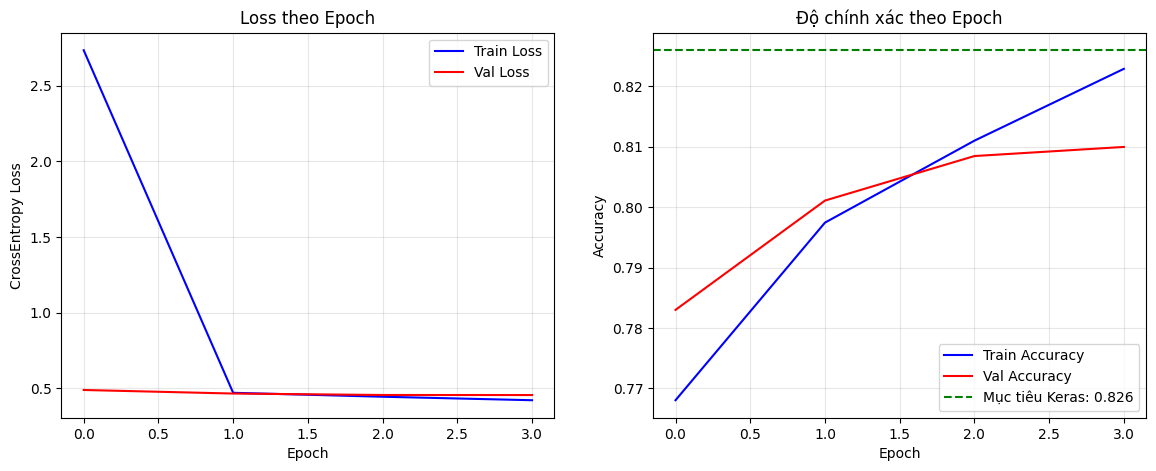

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], 'b-', label='Train Loss')
axes[0].plot(history['val_loss'], 'r-', label='Val Loss')
axes[0].set_title('Loss theo Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('CrossEntropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history['train_acc'], 'b-', label='Train Accuracy')
axes[1].plot(history['val_acc'], 'r-', label='Val Accuracy')
axes[1].axhline(y=0.826, color='green', linestyle='--', label='Mục tiêu Keras: 0.826')
axes[1].set_title('Độ chính xác theo Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.show()


## **Lưu Mô hình**

In [11]:
# Xác định đường dẫn đích trên Google Drive (cùng thư mục chứa dữ liệu và notebook)
save_dir = '/content/drive/MyDrive/P2_Gender_ObjDetection'
save_path = os.path.join(save_dir, 'gender_cnn_basic.pth')

# Tiến hành lưu trọng số mô hình
torch.save(model.state_dict(), save_path)
print(f"Đã lưu mô hình thành công tại: {save_path}")

Đã lưu mô hình thành công tại: /content/drive/MyDrive/P2_Gender_ObjDetection/gender_cnn_basic.pth


In [13]:
print("=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===")
summary(model, input_size=(1, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "kernel_size"])

=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
GenderCNN                                [1, 1, 64, 64]            [1, 2]                    --                        --
├─Conv2d: 1-1                            [1, 1, 64, 64]            [1, 32, 64, 64]           320                       [3, 3]
├─ReLU: 1-2                              [1, 32, 64, 64]           [1, 32, 64, 64]           --                        --
├─MaxPool2d: 1-3                         [1, 32, 64, 64]           [1, 32, 32, 32]           --                        2
├─Conv2d: 1-4                            [1, 32, 32, 32]           [1, 64, 32, 32]           18,496                    [3, 3]
├─ReLU: 1-5                              [1, 64, 32, 32]           [1, 64, 32, 32]           --                        --
├─MaxPool2d: 1-6                         [1, 64, 32, 32]           [1, 64, 16, 16]           --                        2
├─Flatte